# Part 4 — CNN Classification
Balance via Part 2 · Train CNN · Evaluate with f1-score

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import re

# silent warnings
import warnings
from src.augmentation import LeafAugmenter
from src.data import LeafLoader
from src.model import LeafClassifier

warnings.filterwarnings("ignore", category=UserWarning, module="tensorflow")

I0000 00:00:1787757582.406390 2937552 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787757582.455873 2937552 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787757584.291157 2937552 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
root = Path("..")
output_dir = str(root / "augmented_directory")
augmented_dir = Path(output_dir)

In [3]:
print("Balancing dataset...")
loader = LeafLoader()
augmenter = LeafAugmenter(loader=loader)
print("Before:", loader.counts)
augmenter.balance_dataset(
    loader.images, max_len=loader.majority_count, out_dir=str(augmented_dir)
)
balanced = LeafLoader(data_path=augmented_dir)
print("After:", balanced.counts)

Balancing dataset...
Before: {'Apple_Black_rot': 626, 'Apple_rust': 275, 'Grape_Black_rot': 1178, 'Grape_spot': 1075, 'Apple_scab': 629, 'Grape_healthy': 422, 'Apple_healthy': 1646, 'Grape_Esca': 1382}
After: {'Apple_Black_rot': 1646, 'Apple_rust': 1646, 'Grape_Black_rot': 1646, 'Grape_spot': 1646, 'Apple_scab': 1646, 'Grape_healthy': 1646, 'Apple_healthy': 1646, 'Grape_Esca': 1646}


In [4]:
EPOCHS = 100
TARGET_ACC = 0.9
PATIENCE = 10

print(f"\nTraining CNN...")
classifier = LeafClassifier(max_images=100)
m, history, train_ds, val_ds, test_ds, classnames = classifier.train(
    train_dir=output_dir,
    epochs=EPOCHS,
    target_acc=TARGET_ACC,
    patience=PATIENCE,
)


Training CNN...
Found 13168 files belonging to 8 classes.
Using 10535 files for training.
Using 2633 files for validation.


E0000 00:00:1787757609.001314 2937552 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Classes (8): ['Apple_Black_rot', 'Apple_healthy', 'Apple_rust', 'Apple_scab', 'Grape_Black_rot', 'Grape_Esca', 'Grape_healthy', 'Grape_spot']
Epoch 1/100


/goinfre/stamim/Leaffliction/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - accuracy: 0.8542 - loss: 0.4111
Per-class F1: Apple_Black_rot=0.913, Apple_healthy=0.918, Apple_rust=0.974, Apple_scab=0.907, Grape_Black_rot=0.851, Grape_Esca=0.832, Grape_healthy=0.975, Grape_spot=0.966
Worst class: Grape_Esca (0.8322)
297/297 ━━━━━━━━━━━━━━━━━━━━ 139s 450ms/step - accuracy: 0.8542 - loss: 0.4111 - val_accuracy: 0.9176 - val_loss: 0.2060 - val_f1_Apple_Black_rot: 0.9133 - val_f1_Apple_healthy: 0.9176 - val_f1_Apple_rust: 0.9737 - val_f1_Apple_scab: 0.9073 - val_f1_Grape_Black_rot: 0.8506 - val_f1_Grape_Esca: 0.8322 - val_f1_Grape_healthy: 0.9751 - val_f1_Grape_spot: 0.9662
Epoch 2/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.9333 - loss: 0.1726
Per-class F1: Apple_Black_rot=0.961, Apple_healthy=0.961, Apple_rust=0.980, Apple_scab=0.934, Grape_Black_rot=0.887, Grape_Esca=0.864, Grape_healthy=0.987, Grape_spot=0.982
Worst class: Grape_Esca (0.8645)
297/297 ━━━━━━━━━━━━━━━━━━━━ 127s 426ms/step - accuracy: 0.93

In [5]:
print("\nEvaluating...")
val_ds = classifier.loader.load_datasets(output_dir)[1]
classifier.evaluate(val_ds)


Evaluating...
Found 13168 files belonging to 8 classes.
Using 10535 files for training.
Using 2633 files for validation.
83/83 ━━━━━━━━━━━━━━━━━━━━ 21s 256ms/step

Accuracy: 0.9597  (target: >95%)

                 precision    recall  f1-score   support

Apple_Black_rot       0.97      0.98      0.97       320
     Apple_rust       0.98      0.98      0.98       317
Grape_Black_rot       0.98      1.00      0.99       324
     Grape_spot       0.99      0.95      0.97       320
     Apple_scab       0.88      0.94      0.91       355
  Grape_healthy       0.93      0.87      0.90       311
  Apple_healthy       0.98      0.99      0.98       358
     Grape_Esca       0.99      0.96      0.98       328

       accuracy                           0.96      2633
      macro avg       0.96      0.96      0.96      2633
   weighted avg       0.96      0.96      0.96      2633



(np.float64(0.9597417394606912),
 array([0, 6, 7, ..., 3, 0, 4], shape=(2633,), dtype=int32),
 array([0, 4, 5, ..., 3, 0, 4], shape=(2633,)),
 array([[314,   2,   2,   0,   0,   0,   1,   1],
        [  1, 312,   1,   3,   0,   0,   0,   0],
        [  0,   0, 324,   0,   0,   0,   0,   0],
        [  6,   5,   3, 305,   1,   0,   0,   0],
        [  2,   0,   0,   0, 333,  17,   2,   1],
        [  0,   0,   0,   0,  38, 271,   1,   1],
        [  1,   0,   1,   1,   2,   0, 353,   0],
        [  1,   0,   0,   0,   6,   3,   3, 315]]))

[PosixPath('../test/Unit_test1'), PosixPath('../test/Unit_test2')]
True
True

Found 10 test images

Test accuracy: 10.00%  (1/10)

                 precision    recall  f1-score   support

Apple_Black_rot       1.00      1.00      1.00         1
  Apple_healthy       0.00      0.00      0.00         2
     Apple_rust       0.00      0.00      0.00         1
     Apple_scab       0.00      0.00      0.00         1
Grape_Black_rot       0.00      0.00      0.00         2
     Grape_Esca       0.00      0.00      0.00         1
  Grape_healthy       0.00      0.00      0.00         1
     Grape_spot       0.00      0.00      0.00         1

       accuracy                           0.10        10
      macro avg       0.12      0.12      0.12        10
   weighted avg       0.10      0.10      0.10        10

Details:
  [OK   ] Apple_Black_rot1.JPG            true=Apple_Black_rot            pred=Apple_Black_rot
  [WRONG] Apple_healthy1.JPG              true=Apple_healthy              pred

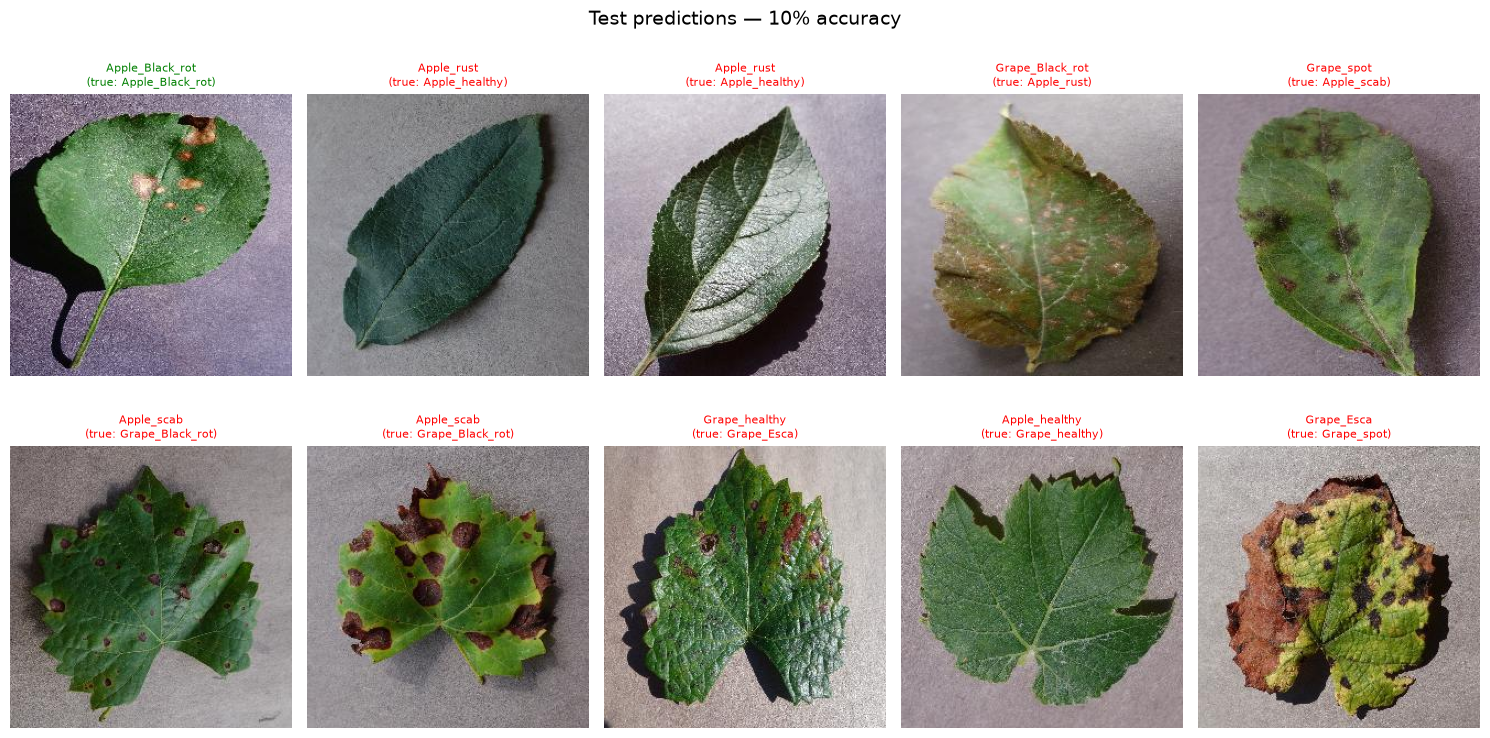

In [6]:
test_images = [root / "test" / d for d in ["Unit_test1", "Unit_test2"]]
print(test_images)

for d in test_images:
    print(d.exists())

acc, details = classifier.test_on_images(test_images)

if details:
    classifier.show_predictions(test_images, details, acc)

In [7]:
model_dir = str(root / "model")
classifier.save(out_dir=model_dir)

zip_path = classifier.zip_artifacts(
    train_dir=output_dir, model_dir=model_dir, out_zip=str(root / "model.zip")
)
classifier.sign(zip_path=zip_path, sig_file=str(root / "signature.txt"))

Model saved to ../model
Zipped → ../model.zip
Signed → ../signature.txt
  31988be9176ccf760bf7c68cdfa3db11654e8d1a  model.zip


'31988be9176ccf760bf7c68cdfa3db11654e8d1a  model.zip'